In [1]:
# 캐글 spaceship titanic 미니 프로젝트 : 분석, 시각화, 전처리, 머신러닝, 튜닝까지

In [2]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

In [3]:
train = pd.read_csv("../../data/spaceship-titanic/train.csv")
test = pd.read_csv("../../data/spaceship-titanic/test.csv")
print( train.shape, test.shape )
display( train.head() )

(8693, 14) (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
print(train['Transported'].value_counts())

Transported
True     4378
False    4315
Name: count, dtype: int64


In [5]:
print( train.isna().sum() )

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


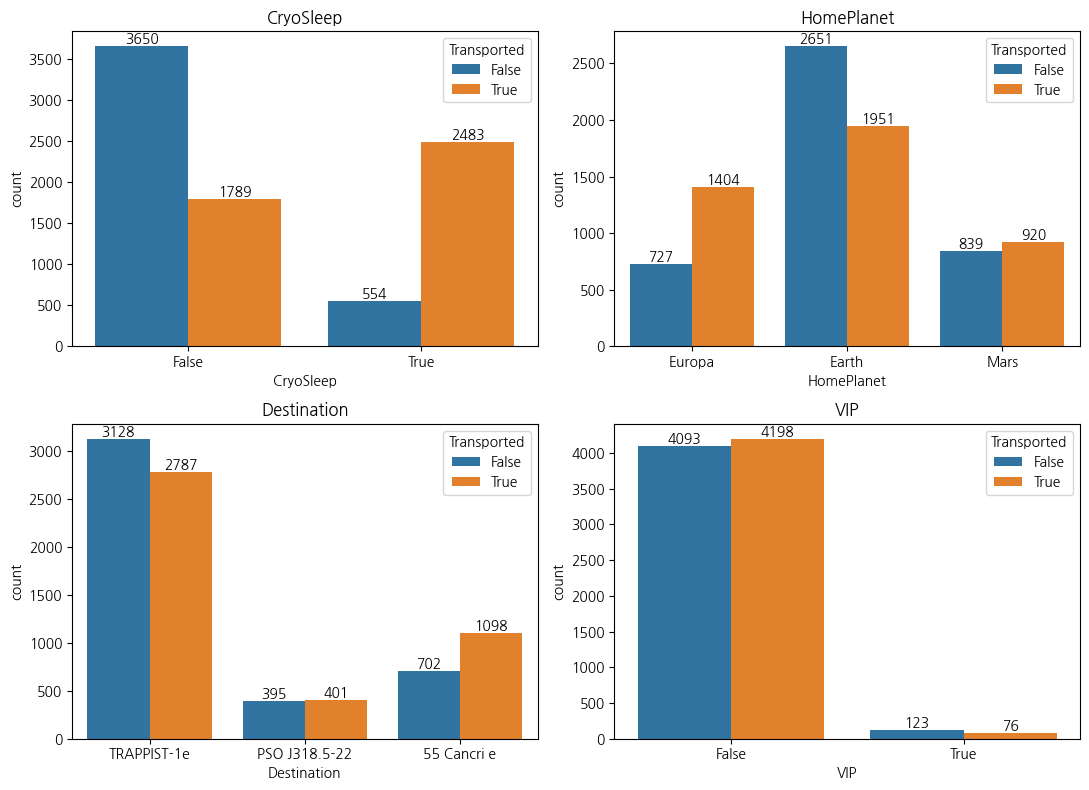

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ['CryoSleep', 'HomePlanet', 'Destination', 'VIP']):
    sns.countplot(data=train, x=col, hue='Transported', ax=ax)
    ax.set_title(col)
    for i in ax.containers:
        ax.bar_label(i)
plt.tight_layout()
plt.show()

In [8]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
train['Spent'] = train[spend_cols].sum(axis=1) > 0 # df['추가할_컬럼'] = 계산식, axis=1은 가로로 더한다.
train.head(3)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Spent
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,True


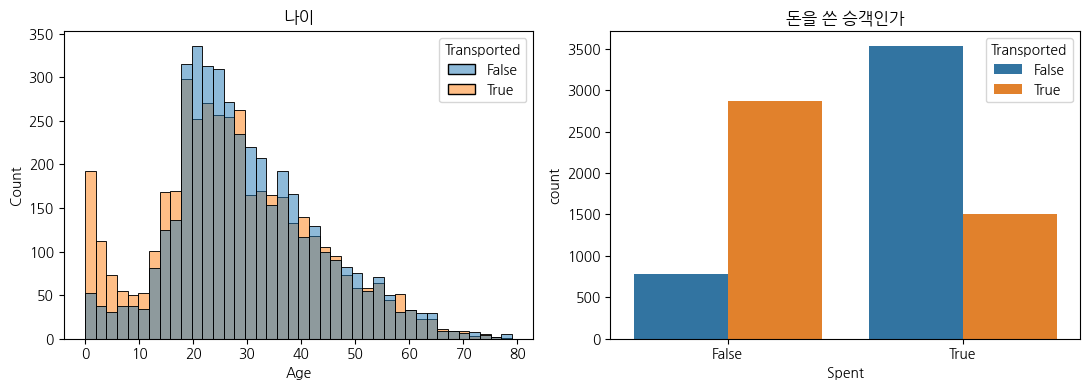

In [9]:
plt.figure(figsize=(11,4))
plt.subplot(121)
sns.histplot(data=train, x='Age', hue='Transported', bins=40)
plt.title("나이")
plt.subplot(122)
sns.countplot(data=train, x='Spent', hue='Transported')
plt.title("돈을 쓴 승객인가")
plt.tight_layout()
plt.show()

In [10]:
df = pd.concat([train, test], ignore_index=True)

In [11]:
# 'B', '0', 'P' <-- 'B/0/P', '/'로 나뉘서 각 컬럼에 넣는다.
df[ ['Deck', 'CabinNum', 'Side'] ] = df['Cabin'].str.split('/', expand=True)
df.head(3)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Spent,Deck,CabinNum,Side
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,False,B,0,P
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,True,F,0,S
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,True,A,0,S


In [12]:
df['Group'] = df['PassengerId'].str[:4] # 0003 <-- 0003_01, 0003 <-- 0003_02
df['GroupSize'] = df.groupby('Group')['Group'].transform('count')
display( df[ ['PassengerId', 'Group', 'GroupSize', 'Cabin', 'Deck', 'Side'] ].head() )

,PassengerId,Group,GroupSize,Cabin,Deck,Side
0,0001_01,0001,1,B/0/P,B,P
1,0002_01,0002,1,F/0/S,F,S
2,0003_01,0003,2,A/0/S,A,S
3,0003_02,0003,2,A/0/S,A,S
4,0004_01,0004,1,F/1/S,F,S


In [13]:
df['TotalSpend'] = df[spend_cols].sum(axis=1)
df.head(3)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,Transported,Spent,Deck,CabinNum,Side,Group,GroupSize,TotalSpend
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,0.0,Maham Ofracculy,False,False,B,0,P,0001,1,0.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,44.0,Juanna Vines,True,True,F,0,S,0002,1,736.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,49.0,Altark Susent,False,True,A,0,S,0003,2,10383.0


In [14]:
# CryoSleep 컬럼이 결측치 이면서 돈을 쓴 사람은 냉동수면중이 아니니까 False 를 채우자
df.loc[ df['CryoSleep'].isna() & (df['TotalSpend'] > 0), 'CryoSleep' ]

98       NaN
104      NaN
152      NaN
224      NaN
314      NaN
        ... 
12609    NaN
12648    NaN
12801    NaN
12902    NaN
12923    NaN
Name: CryoSleep, Length: 174, dtype: object

In [15]:
df.loc[ df['CryoSleep'].isna() & (df['TotalSpend'] > 0), 'CryoSleep' ] = False # 냉동수면중이 아니다

In [16]:
df['CryoSleep'].isna().sum() # 136명 결측치는 True 로 채우자

136

In [17]:
df['CryoSleep'] = df['CryoSleep'].fillna(True) # fill 채운다, na : 결측치

In [18]:
df['CryoSleep'].isna().sum() # 0 <-- 결측치 채우기 성공!

0

In [19]:
df[spend_cols] = df[spend_cols].fillna(0) # 0으로 결측치 채우기

In [20]:
df.isna().sum() # Transported  4277 <-- test 에 정답이 없기 때문
# 채워야할 컬럼들 : HomePlanet  288, Destination  274, Age  270, VIP  296, Deck  299, Side  299
# 결측치 안 쓸 컬럼들 : Name, Transported, Spent, CabinNum

PassengerId        0
HomePlanet       288
CryoSleep          0
Cabin            299
Destination      274
Age              270
VIP              296
RoomService        0
FoodCourt          0
ShoppingMall       0
Spa                0
VRDeck             0
Name             294
Transported     4277
Spent           4277
Deck             299
CabinNum         299
Side             299
Group              0
GroupSize          0
TotalSpend         0
dtype: int64

In [21]:
df['Age'] = df['Age'].fillna( df['Age'].median() ) # 중앙값으로 채우기

In [22]:
df['Age'].isna().sum()

0

In [23]:
df['VIP'] = df['VIP'].fillna(False) # 최빈값(가장 많이 나온 값)으로 채운다.

In [24]:
df['VIP'].isna().sum()

0

In [25]:
df['HomePlanet'].mode() # mode() : 가장 많이 나온 값
# 0  Earth <-- 인덱스  값

0    Earth
Name: HomePlanet, dtype: object

In [26]:
df['HomePlanet'].mode()[0] # 인덱스 0 : 첫번째의 값 --> 'Earth'

'Earth'

In [27]:
for col in ['HomePlanet', 'Destination', 'Deck', 'Side']:
    print(f"df[{col}].mode(): {df[col].mode()}")
    df[col] = df[col].fillna( df[col].mode()[0] ) # [0] <-- 인덱스 0 : 첫번째

df[HomePlanet].mode(): 0    Earth
Name: HomePlanet, dtype: object
df[Destination].mode(): 0    TRAPPIST-1e
Name: Destination, dtype: object
df[Deck].mode(): 0    F
Name: Deck, dtype: object
df[Side].mode(): 0    S
Name: Side, dtype: object


In [28]:
df.isna().sum()

PassengerId        0
HomePlanet         0
CryoSleep          0
Cabin            299
Destination        0
Age                0
VIP                0
RoomService        0
FoodCourt          0
ShoppingMall       0
Spa                0
VRDeck             0
Name             294
Transported     4277
Spent           4277
Deck               0
CabinNum         299
Side               0
Group              0
GroupSize          0
TotalSpend         0
dtype: int64

In [29]:
print( df.drop(columns=['Transported', 'Cabin', 'CabinNum', 'Name', 'Spent']).isna().sum().sum(), "<- 남은 빈칸" ) # drop 등의 df의 함수들은 원본 유지됨.

0 <- 남은 빈칸


In [30]:
df.isna().sum()

PassengerId        0
HomePlanet         0
CryoSleep          0
Cabin            299
Destination        0
Age                0
VIP                0
RoomService        0
FoodCourt          0
ShoppingMall       0
Spa                0
VRDeck             0
Name             294
Transported     4277
Spent           4277
Deck               0
CabinNum         299
Side               0
Group              0
GroupSize          0
TotalSpend         0
dtype: int64

In [31]:
pd.set_option('display.max_columns', None) # 모든 컬럼 보기

In [32]:
labeled = df[ df['Transported'].notna() ] # not : 반대, na : 결측치
print( labeled.shape ) # train 데이터 행렬

(8693, 21)


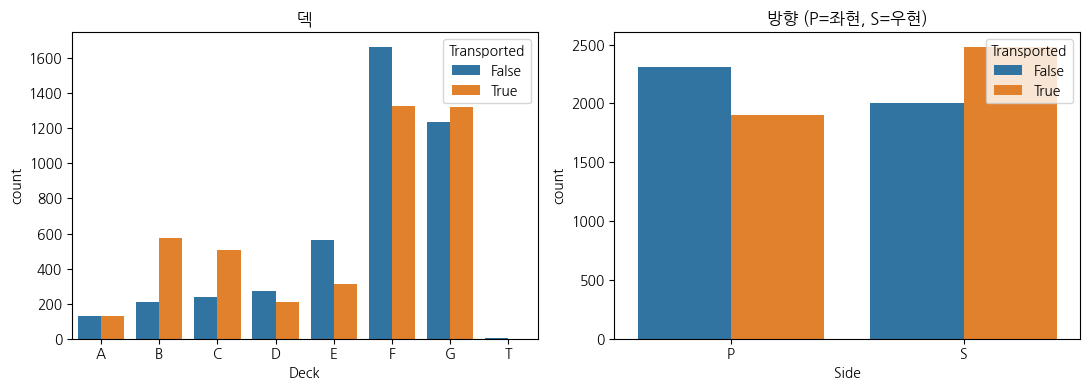

In [33]:
plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
sns.countplot(data=labeled, x='Deck', hue='Transported', order=sorted(labeled['Deck'].unique()))
plt.title("덱")
plt.subplot(1,2,2)
sns.countplot(data=labeled, x='Side', hue='Transported')
plt.title("방향 (P=좌현, S=우현)")
plt.tight_layout()
plt.show()

In [34]:
df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported', 'Spent', 'Deck', 'CabinNum', 'Side', 'Group',
       'GroupSize', 'TotalSpend'],
      dtype='object')

In [35]:
features = ['CryoSleep', 'VIP', 'Age', 'GroupSize', 'TotalSpend'] + spend_cols + ['HomePlanet', 'Destination', 'Deck', 'Side']
print("features:", features)

X_all = pd.get_dummies(df[features], dtype=int)
print("X_all.columns:", X_all.columns)

features: ['CryoSleep', 'VIP', 'Age', 'GroupSize', 'TotalSpend', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'HomePlanet', 'Destination', 'Deck', 'Side']
X_all.columns: Index(['CryoSleep', 'VIP', 'Age', 'GroupSize', 'TotalSpend', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'HomePlanet_Earth',
       'HomePlanet_Europa', 'HomePlanet_Mars', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e', 'Deck_A',
       'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_T',
       'Side_P', 'Side_S'],
      dtype='object')


In [36]:
X_all.head(3)

,CryoSleep,VIP,Age,GroupSize,TotalSpend,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Destination_55 Cancri e,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
0,False,False,39.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0
1,False,False,24.0,1,736.0,109.0,9.0,25.0,549.0,44.0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1
2,False,True,58.0,2,10383.0,43.0,3576.0,0.0,6715.0,49.0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1


In [37]:
is_train = df['Transported'].notna()
is_train

0         True
1         True
2         True
3         True
4         True
         ...  
12965    False
12966    False
12967    False
12968    False
12969    False
Name: Transported, Length: 12970, dtype: bool

In [38]:
X = X_all[is_train]
y = df.loc[ is_train, 'Transported' ].astype(bool)

In [39]:
# ML 코딩 5단계 : 1. 훈련/테스트 데이터 분리 -> 2. ML 알고리즘 선택 -> 3. 훈련 -> 4. 평가 -> 5. 예측

In [40]:
# 1. 훈련/테스트 데이터 분리
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_val.shape)

(6954, 26) (1739, 26)


In [41]:
tree = DecisionTreeClassifier(max_depth=5, random_state=42) # 2. ML 알고리즘 선택
tree.fit(X_train, y_train) # 3. 훈련
print(f"훈련 점수: {tree.score(X_train, y_train)*100:.2f}점") # 4. 평가
print(f"테스트 점수: {tree.score(X_val, y_val)*100:.2f}점")

훈련 점수: 79.67점
테스트 점수: 79.01점


In [42]:
from sklearn.tree import plot_tree

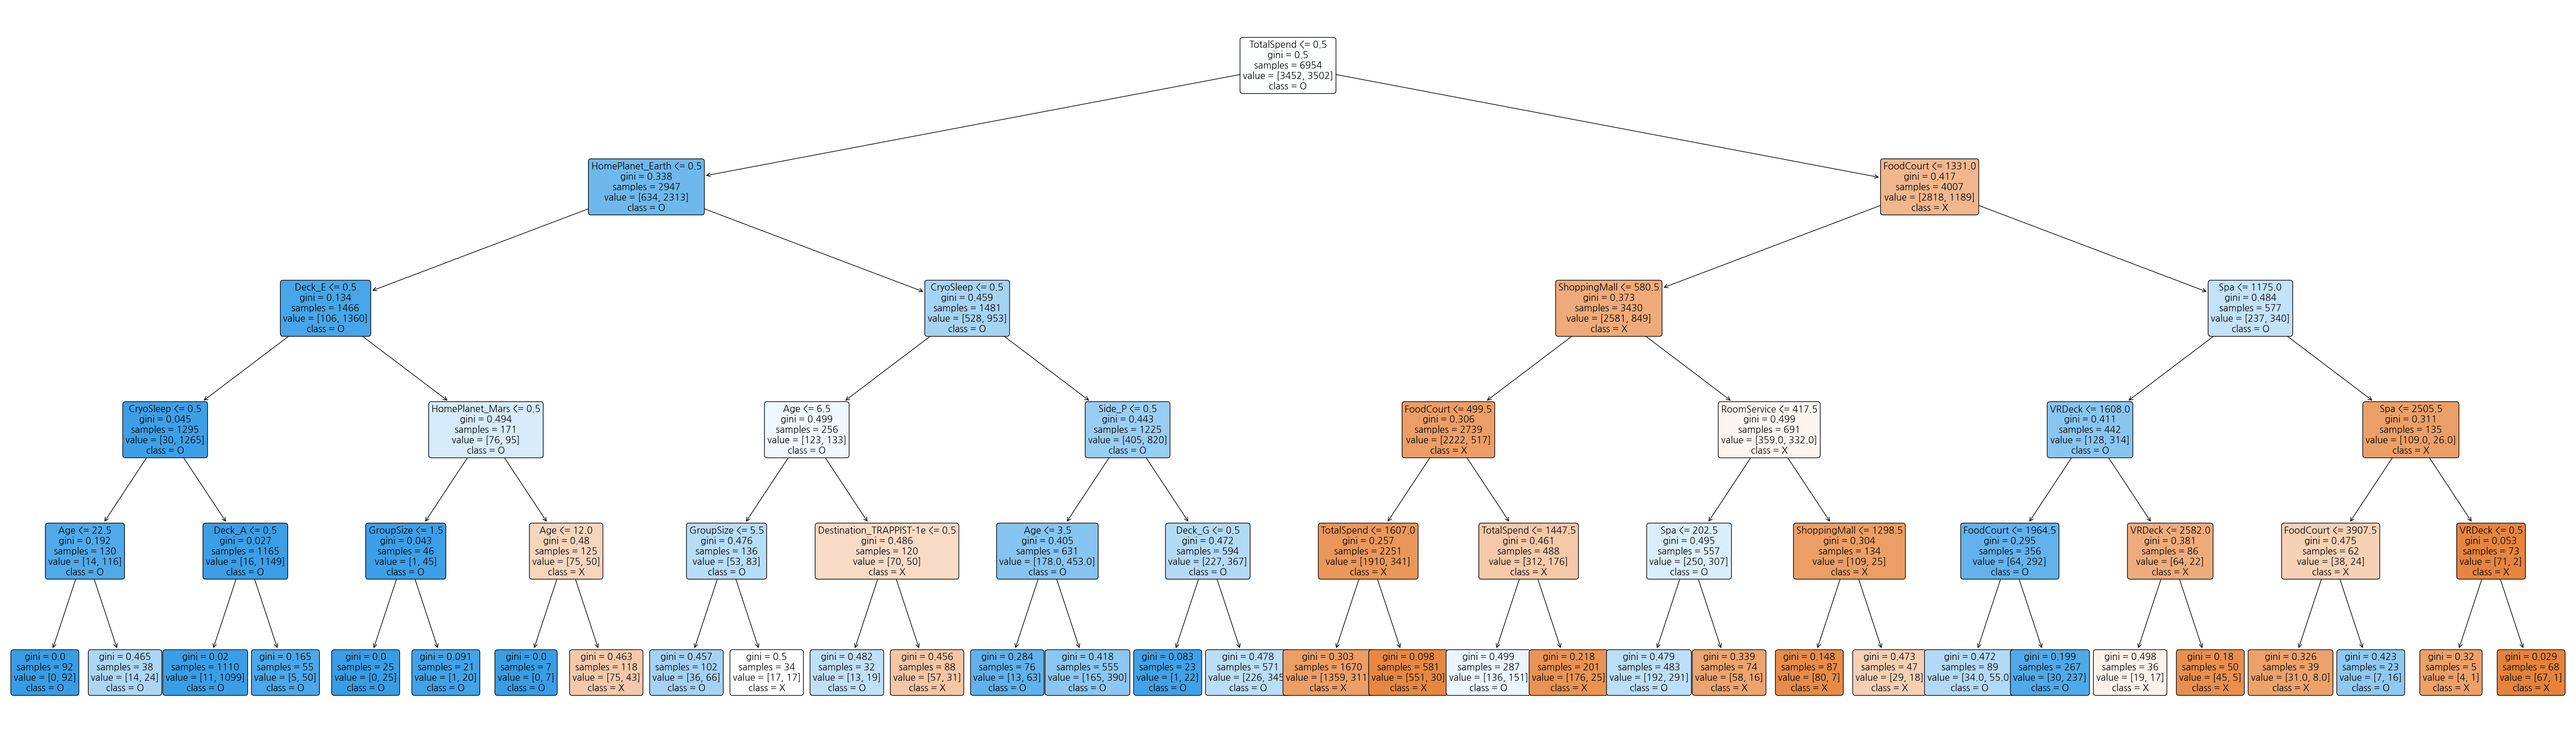

In [43]:
plt.figure(figsize=(70, 20))
plot_tree(tree, feature_names=X_train.columns, class_names=['X', 'O'], filled=True, rounded=True, fontsize=14)
plt.savefig('tree1.png')
plt.show()

In [44]:
models = {
    "의사결정나무": DecisionTreeClassifier(max_depth=5, random_state=42),
    "랜덤포레스트": RandomForestClassifier(random_state=42)
}

In [45]:
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5)
    print(name, "정확도:", round(scores.mean(), 3))

의사결정나무 정확도: 0.778
랜덤포레스트 정확도: 0.779


In [46]:
params = {
    "n_estimators" : [ 100, 300 ],
    "max_depth" : [ 8, 12, None ],
    "min_samples_leaf" : [ 1, 3 ]
}

In [47]:
%%time
grid = GridSearchCV(RandomForestClassifier(random_state=42), params, cv=5, n_jobs=-1)
# n_jobs=-1은 -1은 자동. 논리코어를 모두 사용
grid.fit(X_train, y_train)
# Wall time: 18.5 s <-- n_jobs=-1 <-- 멀티코어가 휠씬 빠름.
# Wall time: 1min 21s <-- n_jobs 없이. 즉 1코어.

CPU times: total: 2.42 s
Wall time: 18.3 s


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [8, 12, None], 'min_samples_leaf': [1, 3],
                         'n_estimators': [100, 300]})

In [48]:
print("최적 조합:", grid.best_params_)
# 최적 조합: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 300}
# RandomForestClassifier(random_state=42, n_estimators=300, max_depth=12, min_samples_leaf=3)

최적 조합: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 300}


In [49]:
print("교차 검증 정확도:", round(grid.best_score_, 3))

교차 검증 정확도: 0.799


In [50]:
best = grid.best_estimator_
print("검증 정확도:", round( best.score(X_val, y_val), 3 ) )

검증 정확도: 0.811


In [51]:
best.feature_importances_

array([0.09474746, 0.00096091, 0.0684403 , 0.0229639 , 0.17075684,
       0.10396668, 0.09364247, 0.07254184, 0.11374661, 0.09160886,
       0.02821891, 0.02323553, 0.0108951 , 0.00623349, 0.00327789,
       0.00712423, 0.00179853, 0.00638139, 0.00572091, 0.0025485 ,
       0.01584177, 0.01550138, 0.01892506, 0.        , 0.01044497,
       0.01047647])

In [52]:
imp = pd.Series( best.feature_importances_, index=X.columns )
imp = imp.sort_values(ascending=False).head(10)
# imp = pd.Series( best.feature_importances_, index=X.columns ).sort_values(ascending=False).head(10) # 1줄
# print(imp)

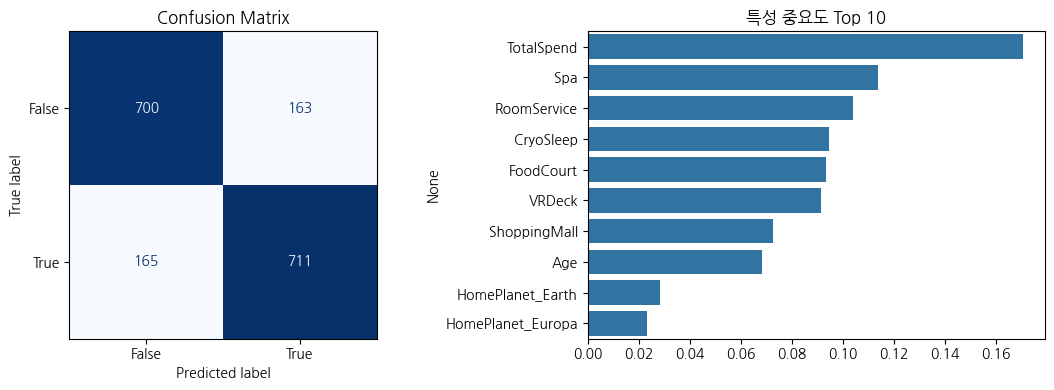

In [53]:
plt.figure(figsize=(11,4))
plt.subplot(121)
ConfusionMatrixDisplay.from_estimator(best, X_val, y_val, ax=plt.gca(), cmap='Blues', colorbar=False)
plt.title("Confusion Matrix")
plt.subplot(122)
# plt.barh(imp.index, imp.values)
# plt.gca().invert_yaxis()  # 중요도가 높은 특성을 위쪽에 표시
sns.barplot(x=imp.values, y=imp.index, orient='h')
plt.title("특성 중요도 Top 10")
plt.tight_layout()
plt.show()

In [54]:
# Kaggle 제출 파일 만들기
pred = best.predict(X_all[~is_train]) # ~ 은 not --> 훈련 데이터가 아니 것 --> 테스트 데이터
submission = pd.DataFrame({"PassengerId": df.loc[~is_train, "PassengerId"], "Transported": pred})
submission.to_csv("submission.csv", index=False)
display(submission)

,PassengerId,Transported
8693,0013_01,True
8694,0018_01,False
8695,0019_01,True
8696,0021_01,True
8697,0023_01,False
...,...,...
12965,9266_02,True
12966,9269_01,True
12967,9271_01,True
12968,9273_01,True


In [55]:
# end